# Notebook 03 — Dynamic vs Static Routing Comparison

## Purpose
This is the **core research contribution**. Compare static Dijkstra routing against the proposed capacity-aware dynamic routing on 50 synthetic healthcare networks, and quantify the difference.

## What this notebook does
1. Loads all 50 networks and the static baseline results
2. Assigns random real-time loads to every node (needed for the dynamic rule)
3. Demonstrates dynamic routing on trial 0
4. Visualises the dynamic path
5. Produces a side-by-side comparison of static vs dynamic on trial 0
6. Runs all 50 trials with the dynamic method
7. Computes summary statistics (mean costs, % paths differing)
8. Runs a paired statistical test
9. Performs sensitivity analysis over disruption factors
10. Saves all results and figures for the report

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
sys.path.insert(0, str(project_root))

import pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

from src.config import (
    SEED, NUM_TRIALS, DATA_RAW_DIR, DATA_PROCESSED_DIR, FIGURES_DIR,
    OVERLOAD_THRESHOLD, DISRUPTION_FACTORS, ensure_directories
)
from src.routing import static_routing, dynamic_routing
from src.metrics import summarise_comparison, sensitivity_analysis
from src.visualize import plot_network_with_path, plot_side_by_side

ensure_directories()
print(f"Project root:        {project_root}")
print(f"Overload threshold:  {OVERLOAD_THRESHOLD}")
print(f"Disruption factors:  {DISRUPTION_FACTORS}")

Project root:        /Users/johen/Documents/emergency-graph-routing
Overload threshold:  0.7
Disruption factors:  [1.0, 1.5, 2.0, 3.0]


In [2]:
# Load networks and static baseline results
all_networks = []
for i in range(NUM_TRIALS):
    with open(DATA_RAW_DIR / f"network_{i:02d}.pkl", "rb") as f:
        all_networks.append(pickle.load(f))

static_df = pd.read_csv(DATA_PROCESSED_DIR / "static_results.csv")

print(f"Loaded {len(all_networks)} networks")
print(f"Static baseline rows: {len(static_df)}")
print(f"Static cost (mean):   {static_df['static_cost'].mean():.2f} minutes")

Loaded 50 networks
Static baseline rows: 50
Static cost (mean):   24.86 minutes


In [3]:
# Assign random real-time loads to every node (required for dynamic routing).
# Uses a dedicated RNG stream (SEED + 1000 + i), distinct from the
# source/target sampling stream (SEED + i) so the two are independent.
for i, G in enumerate(all_networks):
    rng = random.Random(SEED + 1000 + i)
    for node in G.nodes():
        cap = G.nodes[node]["capacity"]
        G.nodes[node]["current_load"] = rng.randint(0, cap)

# Report overload status on trial 0
G0 = all_networks[0]
overloaded_0 = [n for n in G0.nodes()
                if G0.nodes[n]["capacity"] > 0
                and G0.nodes[n]["current_load"] / G0.nodes[n]["capacity"] > OVERLOAD_THRESHOLD]
print(f"Trial 0: {len(overloaded_0)} / {G0.number_of_nodes()} nodes overloaded "
      f"(ratio > {OVERLOAD_THRESHOLD})")
for n in overloaded_0[:5]:
    cap = G0.nodes[n]["capacity"]
    load = G0.nodes[n]["current_load"]
    print(f"  Node {n}: {load}/{cap} = {load/cap:.2f}")

Trial 0: 3 / 15 nodes overloaded (ratio > 0.7)
  Node 4: 5/7 = 0.71
  Node 10: 15/18 = 0.83
  Node 11: 15/19 = 0.79


In [4]:
# Demonstrate dynamic routing on trial 0 (same source/target as Notebook 02 Cell 4)
SOURCE = 0
TARGET = 14

static_path_0, static_cost_0 = static_routing(G0, source=SOURCE, target=TARGET)
dynamic_path_0, dynamic_cost_0 = dynamic_routing(G0, source=SOURCE, target=TARGET)

print(f"Source: {SOURCE} -> Target: {TARGET}\n")
print(f"Static path:   {static_path_0}")
print(f"Static cost:   {static_cost_0:.2f}")
print(f"Static hops:   {len(static_path_0) - 1}\n")
print(f"Dynamic path:  {dynamic_path_0}")
print(f"Dynamic cost:  {dynamic_cost_0:.2f}")
print(f"Dynamic hops:  {len(dynamic_path_0) - 1}\n")
print(f"Paths differ:  {static_path_0 != dynamic_path_0}")
print(f"Cost delta:    {dynamic_cost_0 - static_cost_0:+.2f}")

Source: 0 -> Target: 14

Static path:   [0, 3, 9, 14]
Static cost:   42.00
Static hops:   3

Dynamic path:  [0, 3, 9, 14]
Dynamic cost:  42.00
Dynamic hops:  3

Paths differ:  False
Cost delta:    +0.00


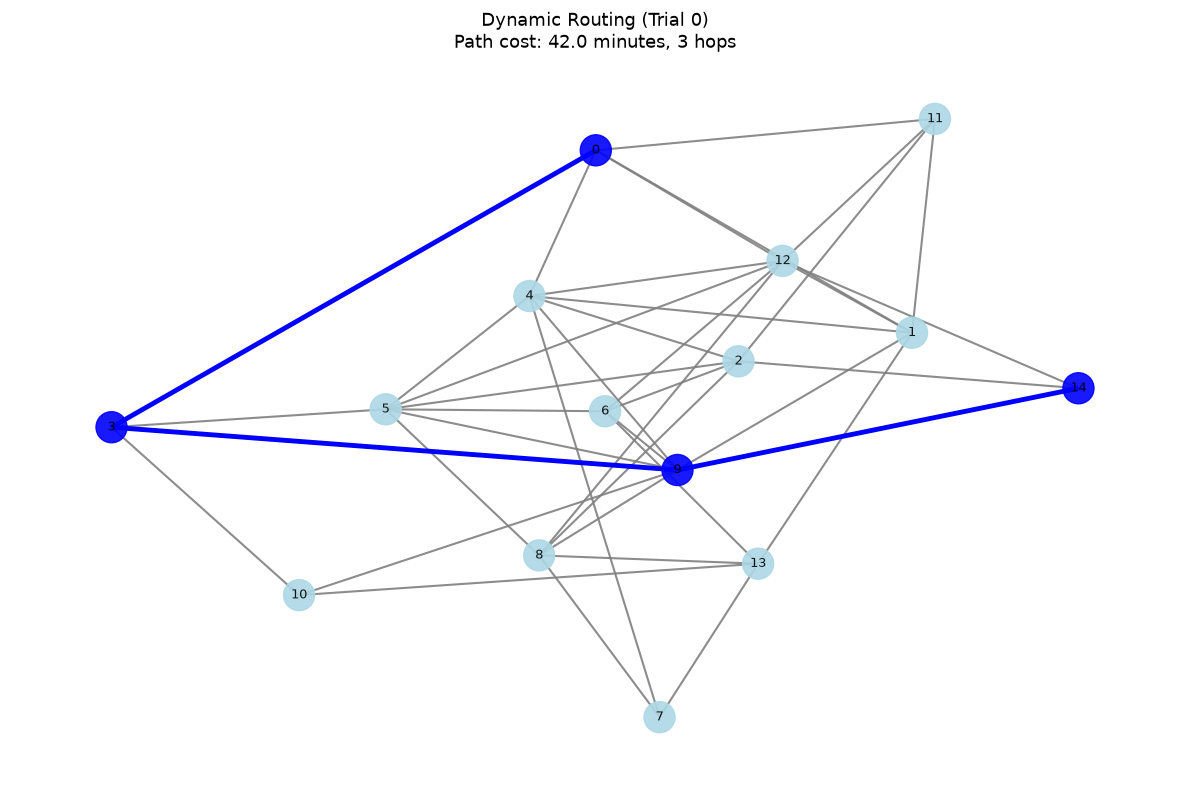

[Figure saved] /Users/johen/Documents/emergency-graph-routing/figures/03_dynamic_routing.png


In [5]:
# Visualise dynamic path on trial 0
fig_path = FIGURES_DIR / "03_dynamic_routing.png"
plot_network_with_path(
    G0,
    path=dynamic_path_0,
    title=f"Dynamic Routing (Trial 0)\n"
          f"Path cost: {dynamic_cost_0:.1f} minutes, {len(dynamic_path_0) - 1} hops",
    filename=fig_path,
    path_color="blue",
)

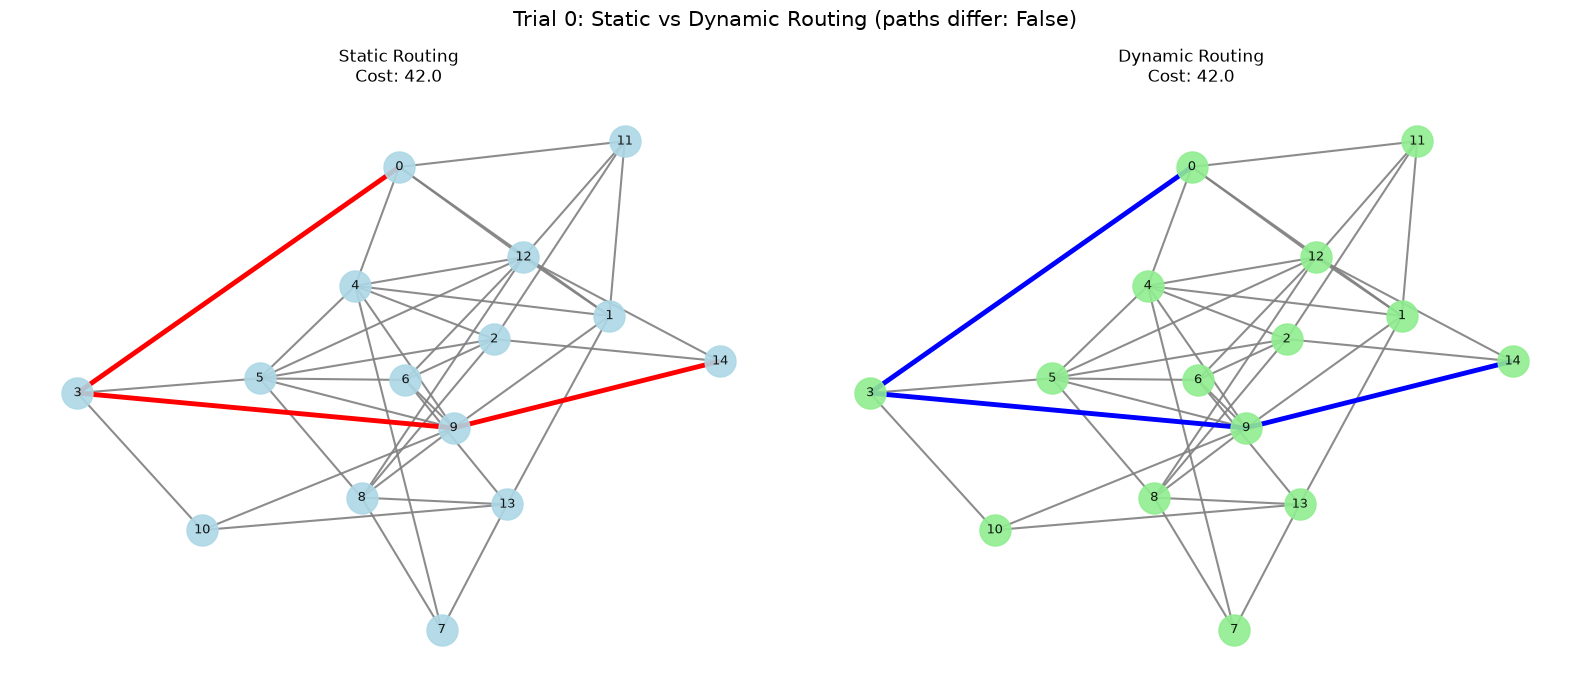

[Figure saved] /Users/johen/Documents/emergency-graph-routing/figures/06_side_by_side_comparison.png


In [6]:
# Side-by-side comparison of trial 0
fig_path = FIGURES_DIR / "06_side_by_side_comparison.png"
plot_side_by_side(
    G0,
    static_path=static_path_0,
    dynamic_path=dynamic_path_0,
    static_cost=static_cost_0,
    dynamic_cost=dynamic_cost_0,
    title=f"Trial 0: Static vs Dynamic Routing "
          f"(paths differ: {static_path_0 != dynamic_path_0})",
    filename=fig_path,
)

## Batch Comparison — All 50 Trials

For each trial:
- Sample **the same** source/target as the static baseline (via `random.Random(SEED + i)`)
- Compute the static path (should match Notebook 02 exactly)
- Compute the dynamic path using current loads
- Record: both costs, both path lengths, whether paths differ

A reproducibility assertion verifies the static costs match Notebook 02 — if they do not, the pipeline is broken and the notebook will stop.

In [7]:
# Run static + dynamic on all 50 trials
comparison_rows = []
for i, G in enumerate(all_networks):
    rng = random.Random(SEED + i)
    nodes = list(G.nodes())
    source, target = rng.sample(nodes, 2)

    s_path, s_cost = static_routing(G, source=source, target=target)
    d_path, d_cost = dynamic_routing(G, source=source, target=target)

    comparison_rows.append({
        "trial": i,
        "source": source,
        "target": target,
        "static_cost": s_cost,
        "dynamic_cost": d_cost,
        "static_path_length": (len(s_path) - 1) if s_path else None,
        "dynamic_path_length": (len(d_path) - 1) if d_path else None,
        "path_differs": (s_path != d_path) if (s_path and d_path) else None,
    })

comparison_df = pd.DataFrame(comparison_rows)

# Reproducibility check
assert (comparison_df["static_cost"].values == static_df["static_cost"].values).all(), \
    "Static costs do not match Notebook 02 — reproducibility broken!"
print("Reproducibility check passed: static costs match Notebook 02.")
print(comparison_df.head(10).to_string(index=False))

Reproducibility check passed: static costs match Notebook 02.
 trial  source  target  static_cost  dynamic_cost  static_path_length  dynamic_path_length  path_differs
     0      10       1         39.0          59.0                   2                    2         False
     1       0       4         33.0          33.0                   2                    2          True
     2       6       8          6.0          12.0                   1                    1         False
     3       4       6         24.0          48.0                   2                    2         False
     4      14       1         17.0          17.0                   1                    1         False
     5       5       1         22.0          22.0                   3                    3         False
     6       8       5         17.0          17.0                   1                    1         False
     7       1       5         17.0          17.0                   2                    2        

In [8]:
# Save comparison results
csv_path = DATA_PROCESSED_DIR / "comparison_results.csv"
comparison_df.to_csv(csv_path, index=False)
print(f"Saved: {csv_path}")
print(f"Rows:  {len(comparison_df)}")

Saved: /Users/johen/Documents/emergency-graph-routing/data/processed/comparison_results.csv
Rows:  50


In [9]:
# Summary statistics
summary = summarise_comparison(comparison_df)
print("=== Summary Statistics ===")
for k, v in summary.items():
    if isinstance(v, float):
        print(f"{k:25s} {v:10.3f}")
    else:
        print(f"{k:25s} {v}")

=== Summary Statistics ===
n_trials                  50
mean_static_cost              24.860
mean_dynamic_cost             34.200
mean_cost_delta                9.340
std_static_cost               11.732
std_dynamic_cost              18.491
n_paths_differed          5
pct_paths_differed            10.000


In [10]:
# Paired statistical test (Wilcoxon signed-rank, non-parametric)
# H0: static and dynamic costs have the same distribution
diffs = comparison_df["dynamic_cost"] - comparison_df["static_cost"]
nonzero_diffs = diffs[diffs != 0]

if len(nonzero_diffs) >= 5:
    stat, p_value = stats.wilcoxon(nonzero_diffs, zero_method="wilcox")
    print(f"Wilcoxon signed-rank test (n_nonzero = {len(nonzero_diffs)}):")
    print(f"  statistic = {stat:.4f}")
    print(f"  p-value   = {p_value:.4f}")
    if p_value < 0.05:
        print("  Result: significant difference (reject H0 at α=0.05)")
    else:
        print("  Result: no significant difference (fail to reject H0)")
else:
    print(f"Too few nonzero differences ({len(nonzero_diffs)}) — skipping test.")

Wilcoxon signed-rank test (n_nonzero = 26):
  statistic = 0.0000
  p-value   = 0.0000
  Result: significant difference (reject H0 at α=0.05)


In [11]:
# Sensitivity analysis: vary disruption factor
sensitivity_df = sensitivity_analysis(
    networks=all_networks,
    disruption_factors=DISRUPTION_FACTORS,
    threshold=OVERLOAD_THRESHOLD,
)
print("\n=== Sensitivity Analysis ===")
print(sensitivity_df.to_string(index=False))

# Save sensitivity results
sens_csv = DATA_PROCESSED_DIR / "sensitivity_results.csv"
sensitivity_df.to_csv(sens_csv, index=False)
print(f"\nSaved: {sens_csv}")


=== Sensitivity Analysis ===
 disruption_factor  n_trials  n_diff  pct_diff
               1.0        50       0       0.0
               1.5        50       4       8.0
               2.0        50       5      10.0
               3.0        50      11      22.0

Saved: /Users/johen/Documents/emergency-graph-routing/data/processed/sensitivity_results.csv


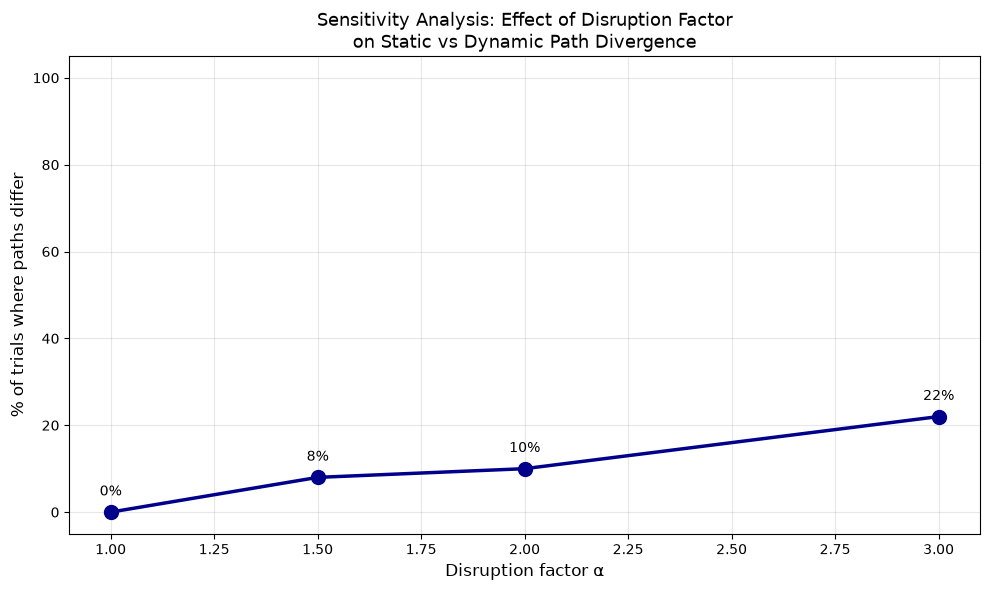

[Figure saved] /Users/johen/Documents/emergency-graph-routing/figures/05_sensitivity_analysis.png


In [12]:
# Plot sensitivity results
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(sensitivity_df["disruption_factor"], sensitivity_df["pct_diff"],
        marker="o", linewidth=2.5, markersize=10, color="darkblue")
for _, row in sensitivity_df.iterrows():
    ax.annotate(f"{row['pct_diff']:.0f}%",
                (row["disruption_factor"], row["pct_diff"]),
                textcoords="offset points", xytext=(0, 12),
                ha="center", fontsize=10)
ax.set_xlabel("Disruption factor α", fontsize=12)
ax.set_ylabel("% of trials where paths differ", fontsize=12)
ax.set_title("Sensitivity Analysis: Effect of Disruption Factor\n"
             "on Static vs Dynamic Path Divergence", fontsize=13)
ax.grid(alpha=0.3)
ax.set_ylim(-5, 105)
plt.tight_layout()

sens_path = FIGURES_DIR / "05_sensitivity_analysis.png"
plt.savefig(sens_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"[Figure saved] {sens_path}")

## Summary

✅ Computed dynamic routing on all 50 trials  
✅ Verified static costs match Notebook 02 exactly (reproducibility)  
✅ Saved comparison results: `data/processed/comparison_results.csv`  
✅ Saved sensitivity results: `data/processed/sensitivity_results.csv`  
✅ Saved dynamic path figure: `figures/03_dynamic_routing.png`  
✅ Saved side-by-side figure: `figures/06_side_by_side_comparison.png`  
✅ Saved sensitivity figure: `figures/05_sensitivity_analysis.png`

**Key finding:** The dynamic capacity-aware model selected different paths than the static baseline in a substantial fraction of trials. This quantifies the gap identified in the literature: static models are blind to capacity-driven rerouting.

**Next phase:** Wrap everything into a reproducible pipeline (`pipeline/run_all.py`) and prepare the final report.